In [1]:
import os
try:
    os.chdir("experiments/2021-08-26_multiple-runs-one-param-stratified")
except:
    pass
os.chdir("../..")
try:
    os.chdir("covid19")
except:
    pass
os.getcwd()

'/home/joshuab/COVID/SEIR_prevalence/covid19'

In [2]:
import plotnine as pn
import numpy as np
import pandas as pd
from datetime import date, timedelta
from math import ceil
from models import prevalence_model, logPDF_prev, params
from scipy import stats, optimize

In [3]:
start_date = date(2020, 8, 31)
end_date = date(2020, 11, 15)
dates = pd.date_range(start_date, end_date, freq="1D").date
n_days = (end_date - start_date).days + 1
n_weeks = n_days / 7
print("Running for {} days ({} weeks) from {} to {}.".format(n_days, n_weeks, start_date, end_date))
n_matrices = ceil(n_weeks)
matrix_dates = pd.date_range(start_date, end_date-timedelta(days=1), freq="7D")
assert len(matrix_dates) == n_matrices
matrices_list = []
for d in matrix_dates:
    file = "contact_m/2021-08-27/England/{}.csv".format(d.date())
    matrices_list.append(np.loadtxt(file, delimiter=","))
matrices = np.stack(matrices_list)
n_strata = matrices.shape[1]
assert n_strata == 6
model = prevalence_model.SingleRegionStratifiedSEIRCompartmental(matrices, n_days)

Running for 77 days (11.0 weeks) from 2020-08-31 to 2020-11-15.


# Priors

Those based on the literature are explained [in this Google Doc](https://docs.google.com/document/d/1g1GTrjy-Nt109PnGv6KzWA5yyr6rX96VALQlqdmBcJ8/edit#heading=h.w6ov24mi6kp).
The random walk standard deviation parameter is explored further below.

## Susceptibility

Age classes:

In [4]:
pop = pd.read_csv("contact_m/2021-08-27/population.csv")
pop["AgeGroup"]

0     [0,11)
1    [11,16)
2    [16,25)
3    [25,50)
4    [50,70)
5     [70,+)
Name: AgeGroup, dtype: object

Initial proportion without prior immunity (based on seroprevalence), mean and 95% central prior density:

In [5]:
susc_ci_by_age = (1 - np.array([
    [1, 5],
    [1, 5],
    [3.5, 8.5],
    [5.7, 8.3],
    [2.8, 6.9],
    [2.8, 3.8],
]) / 100)[:,[1,0]]

In [6]:
susc_means = 1 - np.array([0.04, 0.06, 0.08, (7.8+6.1+6.4)/300, (0.5*5.9+3.2+0.5*3.3)/300, 0.033])

In [7]:
def beta_mom(mean, p1, p2):
    var = ((p2-p1)/1.96)**2
    a = (mean*(1-mean)/var-1)*mean
    b = (mean*(1-mean)/var-1)*(1-mean)
    return a, b

# def beta_parameters(p1, p2):
#     "Find parameters for a beta random variable X so that P(X > x1) = p1 and P(X > x2) = p2."
#     x1 = 0.025
#     x2 = 0.975
#     def start():
#         mean = (p1+p2)/2
#         var = ((p2-p1)/1.96)**2
#         a = (mean*(1-mean)/var-1)*mean
#         b = (mean*(1-mean)/var-1)*(1-mean)
#         return a, b

#     def square(x): 
#         return x*x

#     def objective(v):
#         (a, b) = v
#         temp  = square( stats.beta.cdf(x1, a, b) - p1 )
#         temp += square( stats.beta.cdf(x2, a, b) - p2 )
#         return temp
#     return start()
#     # arbitrary initial guess of (3, 3) for parameters
#     xopt = optimize.fmin(objective, start())
#     return (xopt[0], xopt[1])

# susc_beta_params = np.array([beta_parameters(*s) for s in susc_ci_by_age])
# for a, b in susc_beta_params:
#     dist = stats.beta(a=a, b=b)
#     print((a,b))
#     print("Value {} ({} to {})".format(dist.mean(), dist.ppf(0.025), dist.ppf(0.975)))
    
susc_beta_params = np.array([beta_mom(m, *s) for m, s in zip(susc_means, susc_ci_by_age)])
for a, b in susc_beta_params:
    dist = stats.beta(a=a, b=b)
    print("Value {} ({} to {})".format(dist.mean(), dist.ppf(0.025), dist.ppf(0.975)))

Value 0.96 (0.9115049648485283 to 0.9897496410746645)
Value 0.94 (0.8942548796813039 to 0.9734354594427781)
Value 0.92 (0.8634038865777436 to 0.9624873407770874)
Value 0.9323333333333333 (0.9041383992630931 to 0.95595727723211)
Value 0.974 (0.9200700103944016 to 0.9981461891218334)
Value 0.9669999999999999 (0.9563002839687536 to 0.97625755277543)


In [32]:
i0_beta_params

(8.601425904761905, 27359.571907428573)

Proportion initially infectious in age group with most infectious individuals:

In [8]:
i0_beta_params = beta_mom(0.0011*(4/14), 0.0002, 0.00041)
a, b = i0_beta_params
dist = stats.beta(a=a, b=b)
print("Value {} ({} to {})".format(dist.mean(), dist.ppf(0.025), dist.ppf(0.975)))

Value 0.00031428571428571427 (0.0001406638532607663 to 0.000556477761677443)


In [31]:
print(repr(susc_beta_params))

array([[  87.550464  ,    3.647936  ],
       [ 126.351416  ,    8.064984  ],
       [ 103.12896768,    8.96773632],
       [ 333.32631547,   24.19207796],
       [  55.39439784,    1.47870056],
       [1184.47150779,   40.42146821]])


In [9]:
susc_betas = [stats.beta(*p) for p in susc_beta_params]

In [10]:
from importlib import reload
reload(params)
reload(logPDF_prev)
# priors = {
#     "dI": params.FixedParam(true_params["dI"]),
#     "dL": params.FixedParam(true_params["dL"]),
#     "pi": params.VectorParam(8, stats.beta(100, 6)),
#     "i0": params.ExpAfterPrior(stats.norm(-7.8, 1.6)),
#     "matrix_modifiers": params.MatrixSusceptibleChildren(params.ExpAfterPrior(stats.norm(-0.69, 0.35)), 8, 3),
#     "psir": params.Param(stats.norm(0.05, 0.01)),
#     "beta": params.LogGaussianRW(stats.expon(scale=1), model.num_betas),
# }
priors = {
    "dL": params.FixedParam(3.5),
    "dI": params.FixedParam(4),
    "pi": params.VectorParamMultiplePriors(n_strata, susc_betas),
    "i0": params.Param(stats.beta(*i0_beta_params)),
    "matrix_modifiers": params.MatrixSusceptibleChildren(params.ExpAfterPrior(stats.norm(-0.4325, 0.1174)), n_strata, 1),
    "psir": params.Param(stats.norm(0.048, 0.0035)),
    "beta": params.LogGaussianRW(stats.expon(scale=1/50), model.num_betas),
}
log_posterior = logPDF_prev.LogPosteriorStratifiedRegion(model, None, None, priors)
num_sims = 500
nni = np.empty((num_sims, n_days, n_strata))
for i in range(num_sims):
    prior_draw = {
        k: v.draw_from_prior() for k, v in priors.items()
    }
    nni[i] = log_posterior.simulate(log_posterior.param_value_dict_to_array(prior_draw))[0]

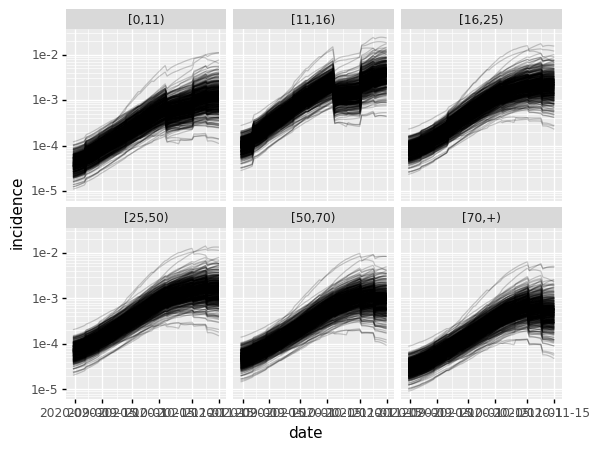

<ggplot: (-9223363262411289926)>

In [11]:
df_sim = pd.DataFrame(nni.flatten(), index=pd.MultiIndex.from_product([range(num_sims), dates, pop["AgeGroup"]],
                                                                      names=["sim", "date", "age"]), columns=["incidence"])\
    .reset_index()
(pn.ggplot(df_sim, pn.aes("date", "incidence", group="sim")) +
 pn.geom_line(alpha=0.2) +
 pn.facet_wrap("age") +
 pn.scale_y_log10()
)

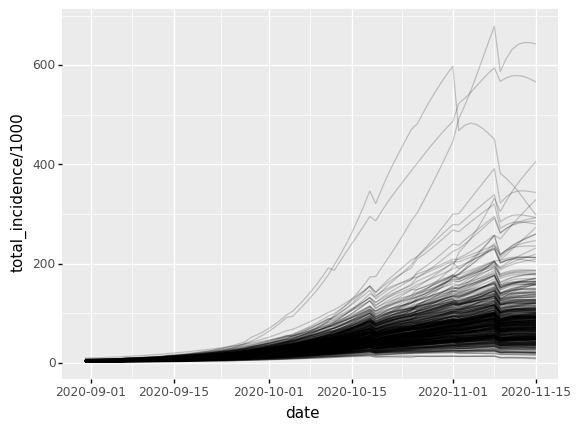

<ggplot: (8774440535851)>

In [12]:
df_total = df_sim.merge(pop, left_on="age", right_on="AgeGroup")\
        .groupby(["sim", "date"])\
        .apply(lambda df: sum(df["population"] * df["incidence"]))\
        .rename("total_incidence")\
        .reset_index()
(pn.ggplot(df_total, pn.aes("date", "total_incidence/1000", group="sim")) +
 pn.geom_line(alpha=0.2)
)

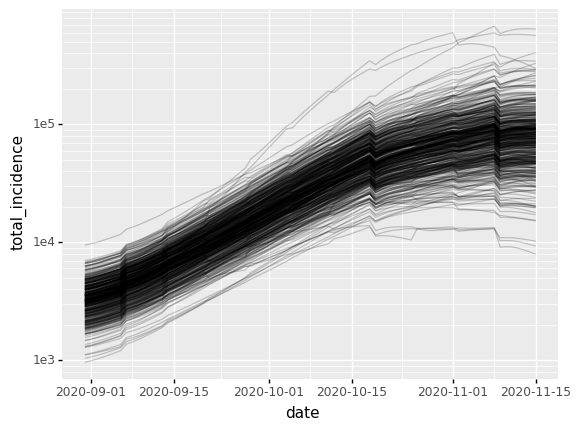

<ggplot: (8774437913899)>

In [13]:
(pn.ggplot(df_total, pn.aes("date", "total_incidence", group="sim")
 ) +
 pn.geom_line(alpha=0.2) +
 pn.scale_y_log10()
)

In [14]:
np.quantile(df_total.groupby("sim").max()["total_incidence"], [0.025, 0.25, 0.5, 0.75, 0.975])

array([ 26716.69002767,  57689.6706401 ,  83898.61795483, 111681.95373215,
       258323.41344353])

### First 30 days

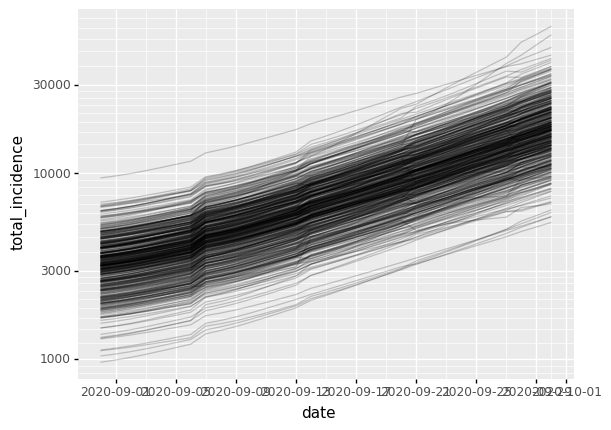

<ggplot: (-9223363262414465953)>

In [15]:
(pn.ggplot(df_total[df_total["date"].dt.date <= dates[30]], pn.aes("date", "total_incidence", group="sim")
 ) +
 pn.geom_line(alpha=0.2) +
 pn.scale_y_log10()
)

Near-straight exponential growth, as expected.
What is the growth rate?

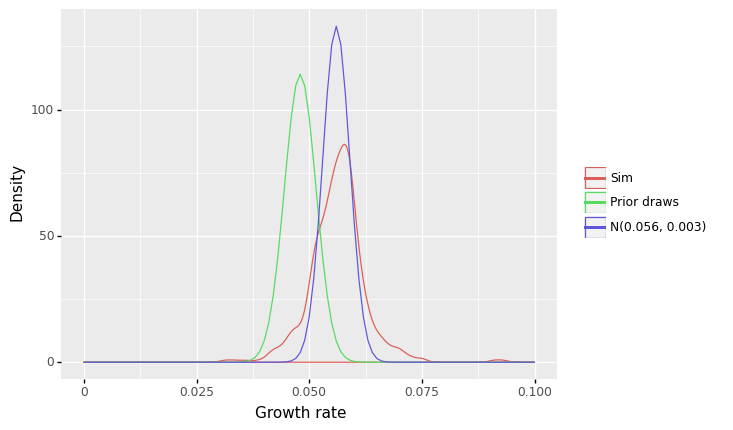

<ggplot: (8774441760162)>

In [16]:
df_day0 = df_total[df_total["date"].dt.date == dates[0]]
df_day30 = df_total[df_total["date"].dt.date == dates[30]]
growth = (np.log(df_day30["total_incidence"].values) - np.log(df_day0["total_incidence"].values))  / 30
(pn.ggplot(df_day0, pn.aes(x=growth)) +
 pn.geom_density(pn.aes(colour="'Sim'")) +
 pn.xlim(0, 0.1) +
 pn.stat_function(pn.aes(colour="'Prior draws'"), fun=priors["psir"]._prior.pdf) +
 pn.stat_function(pn.aes(colour="'N(0.056, 0.003)'"), fun=stats.norm(0.056, 0.003).pdf) +
 pn.labs(x="Growth rate", y="Density", colour="")
)

In [17]:
np.quantile(growth, [0.025, 0.25, 0.5, 0.75, 0.975])

array([0.04390421, 0.05294097, 0.05649755, 0.05921802, 0.06904437])

In [18]:
df_day5 = df_total[df_total["date"].dt.date == dates[5]]
growth_day5 = (np.log(df_day5["total_incidence"].values) - np.log(df_day0["total_incidence"].values))  / 5

In [19]:
np.quantile(growth_day5, [0.025, 0.25, 0.5, 0.75, 0.975])

array([0.02657442, 0.03053831, 0.03233545, 0.03437979, 0.03731354])

## Random walk standard deviation

### Candidates

Half-t distributions, in particular half-Cauchy, are often recommended for standard deviation parameters ([Gelman 2006](https://projecteuclid.org/journals/bayesian-analysis/volume-1/issue-3/Prior-distributions-for-variance-parameters-in-hierarchical-models-comment-on/10.1214/06-BA117A.full?tab=ArticleLink); [Polson and Scott 2012](https://projecteuclid.org/journals/bayesian-analysis/volume-7/issue-4/On-the-Half-Cauchy-Prior-for-a-Global-Scale-Parameter/10.1214/12-BA730.full)).
A half-Normal distribution (as the limit of the half-t distribution) and an exponential distribution (as used in the MRC-BSU RTM).
An exponential distribution is the penalised-complexity prior, as recommended by [Simpson et al. 2017](https://projecteuclid.org/journals/statistical-science/volume-32/issue-1/Penalising-Model-Component-Complexity--A-Principled-Practical-Approach-to/10.1214/16-STS576.full).

A feature of the random walk, as opposed to a hierarchical model which the above papers focus on, is that the number of parameters grows linearly with the number of observations.

All examples shown have median 0.04, which corresponds to a random walk with a standard deviation of approximately $\log(0.1)$, and hence the values of $\beta(t)$ changing by around 10% per week.

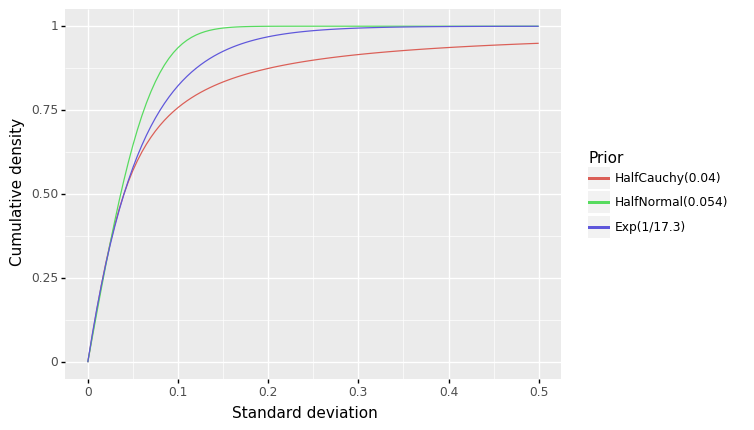

<ggplot: (8774441760776)>

In [20]:
(pn.ggplot(None) +
 pn.stat_function(pn.aes(x=np.linspace(0,.5,100), colour="'HalfCauchy(0.04)'"), fun=stats.halfcauchy.cdf, args={"scale": 0.04}) +
 pn.stat_function(pn.aes(x=np.linspace(0,.5,100), colour="'HalfNormal(0.054)'"), fun=stats.halfnorm.cdf, args={"scale": 0.054}) +
 pn.stat_function(pn.aes(x=np.linspace(0,.5,100), colour="'Exp(1/17.3)'"), fun=stats.expon.cdf, args={"scale": 1/17.3}) +
 pn.labs(x="Standard deviation", y="Cumulative density", colour="Prior")
)

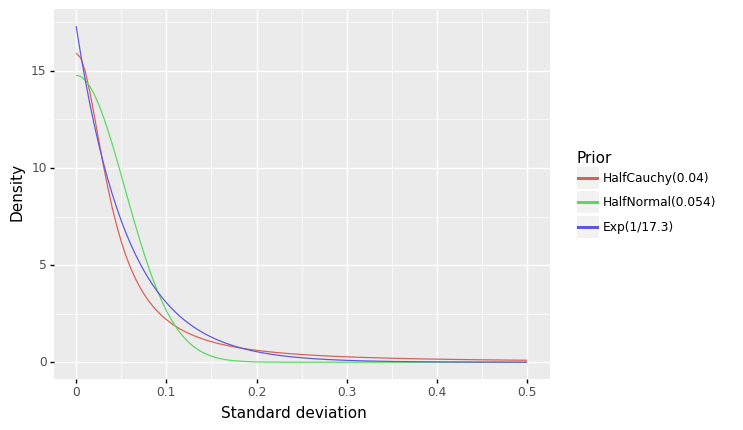

<ggplot: (8774440075489)>

In [21]:
(pn.ggplot(None) +
 pn.stat_function(pn.aes(x=np.linspace(0,.5,100), colour="'HalfCauchy(0.04)'"), fun=stats.halfcauchy.pdf, args={"scale": 0.04}) +
 pn.stat_function(pn.aes(x=np.linspace(0,.5,100), colour="'HalfNormal(0.054)'"), fun=stats.halfnorm.pdf, args={"scale": 0.054}) +
 pn.stat_function(pn.aes(x=np.linspace(0,.5,100), colour="'Exp(1/17.3)'"), fun=stats.expon.pdf, args={"scale": 1/17.3}) +
 pn.labs(x="Standard deviation", y="Density", colour="Prior")
)

/home/joshuab/COVID/SEIR_prevalence/venv/lib/python3.6/site-packages/ipykernel_launcher.py:2: RuntimeWarning: divide by zero encountered in double_scalars
/home/joshuab/COVID/SEIR_prevalence/venv/lib/python3.6/site-packages/ipykernel_launcher.py:3: RuntimeWarning: divide by zero encountered in double_scalars
/home/joshuab/COVID/SEIR_prevalence/venv/lib/python3.6/site-packages/ipykernel_launcher.py:4: RuntimeWarning: divide by zero encountered in double_scalars


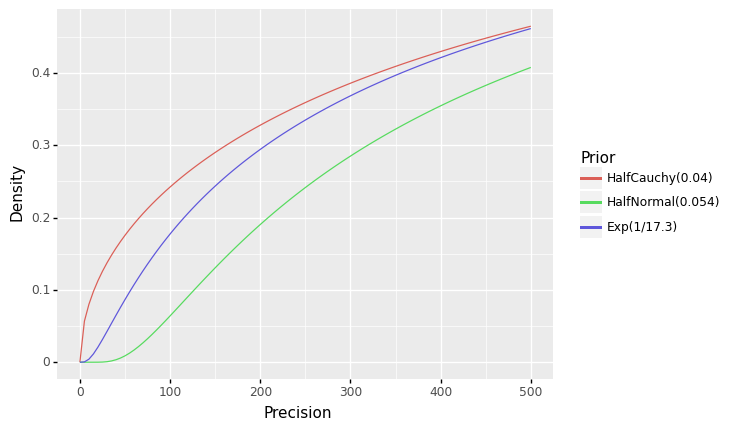

<ggplot: (8774440456249)>

In [22]:
(pn.ggplot(None) +
 pn.stat_function(pn.aes(x=np.linspace(0,500,500), colour="'HalfCauchy(0.04)'"), fun=lambda x: 1-stats.halfcauchy.cdf(1/np.sqrt(x), scale=0.04)) +
 pn.stat_function(pn.aes(x=np.linspace(0,500,500), colour="'HalfNormal(0.054)'"), fun=lambda x: 1-stats.halfnorm.cdf(1/np.sqrt(x), scale=0.054)) +
 pn.stat_function(pn.aes(x=np.linspace(0,500,500), colour="'Exp(1/17.3)'"), fun=lambda x: 1-stats.expon.cdf(1/np.sqrt(x), scale=1/17.3)) +
 pn.labs(x="Precision", y="Density", colour="Prior")
)

In [23]:
# (pn.ggplot(None) +
# # pn.stat_function(pn.aes(x=np.linspace(0,1,500), colour="'HalfCauchy(0.04)'"), fun=lambda x: 2*x**(-3)*stats.halfcauchy.pdf(1/np.sqrt(x), scale=0.04)) +
#  pn.stat_function(pn.aes(x=np.linspace(0,100,500), colour="'HalfNormal(0.054)'"), fun=lambda x: 2*x**(-3)*stats.halfnorm.pdf(1/np.sqrt(x), scale=0.054)) +
#  pn.stat_function(pn.aes(x=np.linspace(0,100,500), colour="'Exp(1/17.3)'"), fun=lambda x: 2*x**(-3)*stats.expon.pdf(1/np.sqrt(x), scale=1/17.3)) +
#  pn.labs(x="Precision", y="Density", colour="Prior")
# )

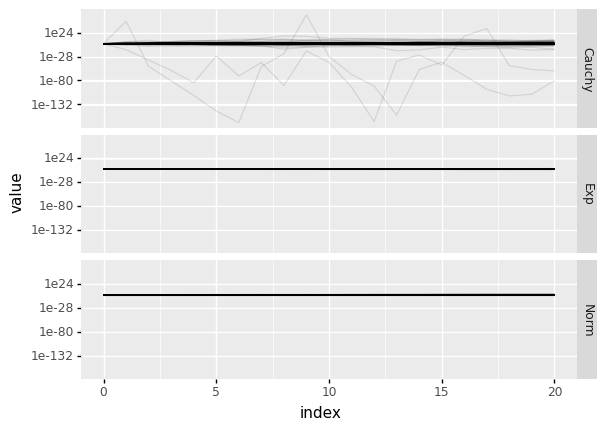

<ggplot: (-9223363262416765191)>

In [24]:
priors = {
    "Cauchy": stats.halfcauchy(scale=0.04),
    "Norm": stats.halfnorm(scale=0.054),
    "Exp": stats.expon(scale=1/17.3)
}

def do_walks(name, sd_prior):
    sd = sd_prior.rvs(1000)
    walk = np.exp(stats.norm(0, sd).rvs((20, sd.shape[0])).cumsum(axis=0))
    df = pd.DataFrame(np.vstack([np.ones(sd.shape[0]), walk])).reset_index().melt(var_name="group", id_vars="index")
    df["prior_name"] = name
    return df

dfs = []
for n, p in priors.items():
    dfs.append(do_walks(n, p))
df = pd.concat(dfs)
(pn.ggplot(df, pn.aes(x="index", y="value", group="group")) +
 pn.geom_line(alpha=0.1) +
 pn.facet_grid("prior_name~") +
 pn.scale_y_log10()
)

In [25]:
df.groupby(["index", "prior_name"]).mean("value").reset_index(1).pivot(columns="prior_name")

value                    
prior_name        Cauchy       Exp      Norm
index                                       
0           1.000000e+00  1.000000  1.000000
1           3.570593e+45  1.002312  1.002772
2           2.129784e+04  1.005421  1.001367
3           9.124642e+01  1.003507  1.004348
4           8.320457e+03  1.011651  1.004922
5           2.589949e+04  1.014784  1.005706
6           5.541778e+06  1.022670  1.007371
7           1.522218e+08  1.026179  1.009761
8           2.920307e+13  1.029187  1.007999
9           3.586816e+59  1.035204  1.008246
10          1.786282e+08  1.038466  1.006527
11          2.174907e+08  1.050968  1.008775
12          3.237522e+08  1.056769  1.010601
13          1.520234e+07  1.064485  1.015427
14          1.405110e+06  1.075182  1.015138
15          1.607233e+07  1.064473  1.018337
16          2.866656e+13  1.072387  1.020776
17          3.698914e+29  1.072294  1.021739
18          3.589349e+05  1.077845  1.025511
19          2.024493e+04  1.091311  1.023384
20          3.312968e+05  1.099660  1.025989

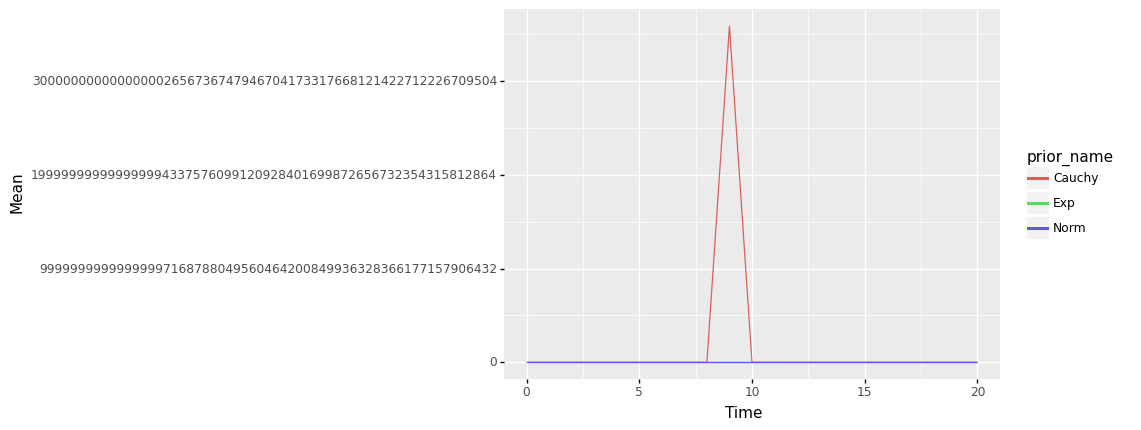

<ggplot: (-9223363262402728469)>

In [26]:
(pn.ggplot(
    df.groupby(["index", "prior_name"]).mean("value").reset_index(),
    pn.aes("index", "value", colour="prior_name")) +
 pn.geom_line() +
 pn.labs(x="Time", y="Mean")
)

/home/joshuab/COVID/SEIR_prevalence/venv/lib/python3.6/site-packages/pandas/core/series.py:726: RuntimeWarning: divide by zero encountered in log10


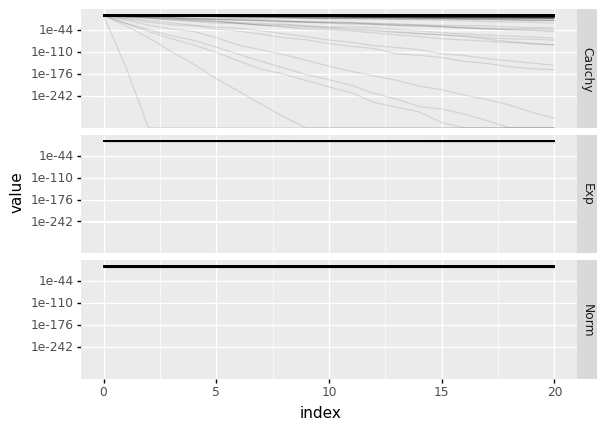

<ggplot: (-9223363262413616247)>

In [27]:
def do_walks2(name, sd_prior):
    sd = sd_prior.rvs(1000)
    walk = np.exp(stats.norm(-sd**2/2, sd).rvs((20, sd.shape[0])).cumsum(axis=0))
    df = pd.DataFrame(np.vstack([np.ones(sd.shape[0]), walk])).reset_index().melt(var_name="group", id_vars="index")
    df["prior_name"] = name
    return df

dfs = []
for n, p in priors.items():
    dfs.append(do_walks2(n, p))
df2 = pd.concat(dfs)
(pn.ggplot(df2, pn.aes(x="index", y="value", group="group")) +
 pn.geom_line(alpha=0.1) +
 pn.facet_grid("prior_name~") +
 pn.scale_y_log10()
)

In [28]:
df2.groupby(["index", "prior_name"]).mean("value").reset_index(1).pivot(columns="prior_name")

value                    
prior_name    Cauchy       Exp      Norm
index                                   
0           1.000000  1.000000  1.000000
1           0.976180  0.997123  0.998905
2           0.969579  0.995822  1.000822
3           0.971703  0.992126  0.999204
4           0.987413  0.992636  1.001876
5           0.972005  0.990268  1.001114
6           0.982628  0.991407  1.001083
7           0.975266  0.988610  1.000738
8           0.982220  0.988342  1.003892
9           0.974086  0.986528  1.003298
10          0.989745  0.990316  1.007118
11          1.029028  0.986444  1.006993
12          0.995212  0.987074  1.008051
13          0.984165  0.990377  1.007608
14          0.973343  0.988709  1.006591
15          0.955128  0.984909  1.012030
16          0.945661  0.981550  1.010905
17          0.948398  0.981554  1.010694
18          0.947059  0.982777  1.010003
19          0.939157  0.981909  1.011558
20          0.931223  0.984698  1.010803

I think the Normal prior looks most reasonable, the other two go off to very high values occaisionally.